# Sociología · INE — Censos de Población y Vivienda 2017 y 2024

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Data-Observatory/datopia-notebooks/blob/main/notebooks/sociologia/ine/demo.ipynb)
[![Licencia](https://img.shields.io/badge/licencia-MIT-blue.svg)](../../../LICENSE)
[![Dataset](https://img.shields.io/badge/dataset-INE%20Censos-green.svg)]()
[![Actualización](https://img.shields.io/badge/actualización-por%20censo-brightgreen.svg)]()
[![Python](https://img.shields.io/badge/python-3.10%2B-blue.svg)]()

---

## Descripción

Acceso a los **microdatos de los Censos de Población y Vivienda 2017 y 2024** del INE (Chile) a
través del **Datopia Lakehouse**: una fila por vivienda, hogar o persona censada, sin descargar
archivos.

La fuente `ine` tiene **cuatro tablas**, y dos de ellas son los mismos datos en distinta forma:

| Tabla (`tipo=`) | Versión | Qué contiene | Tamaño |
|---|---|---|---|
| `censos-poblacionales` | `v1w` (**ancho**) | Una fila por vivienda / hogar / persona y **una columna por variable** (`sexo`, `edad`, `tipo_vivienda`...). | ~62 millones de filas |
| `censos-poblacionales` | `v1l` (**largo**) | Los mismos registros, una fila por **pregunta y respuesta** (`pregunta`, `respuesta`). | ~1.600 millones de filas |
| `division-territorial-censal` | `v1` | Geografía censal: comunas, provincias y regiones; en 2017 también zonas y localidades. | ~16 mil filas |
| `preguntas-respuestas-censo` | `v1` | Diccionario de preguntas y códigos de respuesta de ambos censos. | ~1.200 filas |

Para casi todos los análisis conviene el **formato ancho**. El largo sirve para consultar una
pregunta por su texto, sin saber cómo se llama su columna; la sección 8 muestra cuándo conviene
cada uno.

### Contenido

1. Configuración y autenticación
2. Exploración: las cuatro tablas y las variables disponibles
3. Cómo se conectan las tablas (comuna, vivienda, hogar y persona)
4. Caso 1: población por región, 2017 y 2024
5. Caso 2: pirámide de población
6. Caso 3: tipo de vivienda (y qué hacer cuando las etiquetas cambian entre censos)
7. Caso 4: hogares con internet fijo por región (2024)
8. Formato largo: una consulta para cualquier pregunta (y cuándo conviene cada formato)
9. Tu propia consulta

### Requisitos

Cuenta en el Datopia Lakehouse · Python 3.10+ · Las dependencias se instalan automáticamente

In [1]:
# @title Instalación de dependencias
import importlib, subprocess, sys

for paquete in ["requests", "duckdb", "pandas", "matplotlib"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

import json, os, getpass, pathlib
import requests, duckdb
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

EN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

print("Dependencias listas.")

Dependencias listas.


In [2]:
# @title Configuración de credenciales
print(f"Entorno: {'Google Colab' if EN_COLAB else 'local'}")

URL_API = "https://ee98cnfz7e.execute-api.us-west-2.amazonaws.com/prod"

if EN_COLAB:
    EMAIL = input("Email: ").strip()
    PASSWORD = getpass.getpass("Contraseña: ")
else:
    ruta_cfg = pathlib.Path("../../../config.json")
    if not ruta_cfg.exists():
        raise FileNotFoundError(
            f"Archivo de configuración no encontrado en {ruta_cfg.resolve()}.\n"
            "Copia config.example.json → config.json y completa tus credenciales."
        )
    cfg = json.loads(ruta_cfg.read_text())
    EMAIL = cfg.get("test_user", {}).get("email") or input("Email: ").strip()
    PASSWORD = cfg.get("test_user", {}).get("password") or getpass.getpass(
        "Contraseña: "
    )

print(f"API    : {URL_API}")
usuario, _, dominio = EMAIL.partition("@")
print(f"Usuario: {usuario[:3]}***@{dominio}")   # se enmascara para no dejar el email en las salidas

Entorno: local
API    : https://ee98cnfz7e.execute-api.us-west-2.amazonaws.com/prod
Usuario: do-***@dataobservatory.net


---
## 1. Autenticación y conexión a S3

In [3]:
# Iniciar sesión y obtener credenciales temporales S3
resp_login = requests.post(
    f"{URL_API}/auth/login",
    json={"email": EMAIL, "password": PASSWORD},
    timeout=30,
)
resp_login.raise_for_status()
token = resp_login.json()["id_token"]

resp_s3 = requests.post(
    f"{URL_API}/auth/session/s3",
    headers={"Authorization": f"Bearer {token}"},
    timeout=30,
)
resp_s3.raise_for_status()
creds = resp_s3.json()

print("Sesión iniciada")
print(f"  Bucket : {creds['bucket']}")
print(f"  Región : {creds['region']}")
print(f"  Expira : {creds['expires_at']}")

Sesión iniciada
  Bucket : do-datopia
  Región : us-west-2
  Expira : 2026-11-05T16:35:15+00:00


In [4]:
# Configurar DuckDB con credenciales S3
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs")
con.execute(f"""
    CREATE OR REPLACE SECRET s3 (
        TYPE          S3,
        KEY_ID        '{creds["access_key_id"]}',
        SECRET        '{creds["secret_access_key"]}',
        SESSION_TOKEN '{creds["session_token"]}',
        REGION        '{creds["region"]}'
    )
""")
con.execute("SET enable_http_metadata_cache=true")
con.execute("SET parquet_metadata_cache=true")
con.execute("SET enable_progress_bar=false")
# La lectura remota está limitada por latencia, no por CPU: más hilos de E/S aceleran las consultas.
con.execute("SET threads=128")

BASE_FUENTE = f"s3://{creds['bucket']}/categoria=sociologia/pais=cl/fuente=ine"
BASE_ANCHO = f"{BASE_FUENTE}/tipo=censos-poblacionales/version=v1w"          # microdatos, formato ancho
BASE_LARGO = f"{BASE_FUENTE}/tipo=censos-poblacionales/version=v1l"          # microdatos, formato largo
BASE_ZONAS = f"{BASE_FUENTE}/tipo=division-territorial-censal/version=v1"    # geografía censal
BASE_PREGUNTAS = f"{BASE_FUENTE}/tipo=preguntas-respuestas-censo/version=v1" # diccionario


def leer_censo(base, tipo_registro, anio="*"):
    """SQL de lectura de una partición: `year=` y `tipo_registro=` son carpetas del path.

    Cada año y cada tipo de registro guarda solo sus propias columnas; `union_by_name` las une y las
    que no existen en una partición quedan nulas.
    """
    return (f"read_parquet('{base}/year={anio}/tipo_registro={tipo_registro}/part-*.parquet', "
            "hive_partitioning=true, union_by_name=true)")


# Vistas para que el SQL de las celdas siguientes se lea limpio (no leen nada hasta que se consultan)
for vista in ["viviendas", "hogares", "personas"]:
    con.execute(f"CREATE OR REPLACE VIEW {vista} AS SELECT * FROM {leer_censo(BASE_ANCHO, vista)}")

# Comuna → región. En 2017 la tabla trae una fila por zona censal; se deja una fila por comuna.
con.execute(f"""
    CREATE OR REPLACE VIEW comunas AS
    SELECT DISTINCT cod_comuna, nombre_comuna, cod_provincia, nombre_provincia, cod_region, nombre_region
    FROM read_parquet('{BASE_ZONAS}/part-*.parquet')
""")
con.execute(f"CREATE OR REPLACE VIEW preguntas AS SELECT * FROM read_parquet('{BASE_PREGUNTAS}/part-*.parquet')")

print("DuckDB conectado a S3. Vistas: viviendas, hogares, personas (ancho), comunas, preguntas")

DuckDB conectado a S3. Vistas: viviendas, hogares, personas (ancho), comunas, preguntas


---
## 2. Exploración: las cuatro tablas

### Cuántas filas hay y cómo se reparten

Cada tabla trae un `manifest.json` con las filas de cada partición, así que contar no obliga a leer
los datos. Los **mismos registros** ocupan ~62 millones de filas en formato ancho y ~1.600 millones
en largo (una fila por cada pregunta respondida):

In [5]:
def filas_por_particion(base):
    """Filas por (year, tipo_registro) leídas del manifest.json de la versión (no lee datos)."""
    manifest = con.execute(f"SELECT * FROM read_json('{base}/manifest.json')").df().iloc[0]
    partes = pd.DataFrame([dict(p) for p in manifest["parts"]])
    partes[["year", "tipo_registro"]] = partes["file"].str.extract(r"year=(\d+)/tipo_registro=(\w+)")
    partes["year"] = partes["year"].astype(int)
    return partes.groupby(["year", "tipo_registro"])["row_count"].sum()


tamano = pd.DataFrame({
    "ancho (v1w)": filas_por_particion(BASE_ANCHO),
    "largo (v1l)": filas_por_particion(BASE_LARGO),
})
tamano["preguntas por registro (largo / ancho)"] = (tamano["largo (v1l)"] / tamano["ancho (v1w)"]).round(1)
for columna in ["ancho (v1w)", "largo (v1l)"]:
    tamano[columna] = tamano[columna].map(lambda v: f"{v:,.0f}".replace(",", "."))
tamano

ancho (v1w)  largo (v1l)  preguntas por registro (largo / ancho)
year tipo_registro                                                                 
2017 hogares         5.664.678   11.329.356                                     2.0
     personas       17.574.003  579.942.099                                    33.0
     viviendas       6.499.574   58.496.166                                     9.0
2024 hogares         6.622.597   72.587.867                                    11.0
     personas       18.480.432  777.506.949                                    42.1
     viviendas       7.664.466  121.645.740                                    15.9

### Variables disponibles (formato ancho)

El archivo `dataset.json` describe las ~100 columnas del formato ancho. **No todas existen en los
dos censos**: el cuestionario cambió entre 2017 y 2024, y cada tipo de registro (vivienda, hogar,
persona) tiene sus propias columnas. `variables()` las lista indicando en qué años existe cada una:

In [6]:
# Catálogo de columnas desde dataset.json (descripciones en español)
texto_json = con.execute(f"SELECT content FROM read_text('{BASE_ANCHO}/dataset.json')").fetchone()[0]
catalogo = pd.DataFrame([
    {"variable": c["name"], "rol": c["role"], "descripcion": c["i18n"]["es"]["description"]}
    for c in json.loads(texto_json)["columns"]
])


def variables(tipo_registro, texto=None):
    """Variables de `viviendas`, `hogares` o `personas`, y en qué años existen (opcional: filtrar por texto)."""
    existe = {}
    for anio in (2017, 2024):
        ruta = f"{BASE_ANCHO}/year={anio}/tipo_registro={tipo_registro}/part-00000.parquet"
        existe[anio] = set(con.execute(f"SELECT name FROM parquet_schema('{ruta}')").df()["name"])
    todas = existe[2017] | existe[2024]
    tabla = catalogo[catalogo["variable"].isin(todas) & ~catalogo["rol"].isin(["partition", "technical"])].copy()
    for anio in (2017, 2024):
        tabla[str(anio)] = tabla["variable"].map(lambda v: "✓" if v in existe[anio] else "–")
    if texto:
        tabla = tabla[tabla["variable"].str.contains(texto, case=False)
                      | tabla["descripcion"].str.contains(texto, case=False)]
    return tabla[["variable", "2017", "2024", "descripcion"]].reset_index(drop=True)


variables("personas").head(20)

,variable,2017,2024,descripcion
0,id_vivienda,✓,✓,Identificador de la vivienda. En 2017 es relativo a la zona censal (único junto con id_zona_cens...
1,id_zona_censal_local,✓,–,"Identificador INE de la zona (urbana) o localidad (rural) censal, solo en 2017 (ID_ZONA_LOC). Lo..."
2,id_hogar,✓,✓,Número del hogar dentro de la vivienda. Solo en: 2017 hogares; 2017 personas; 2024 hogares; 2024...
3,grupo_etario,✓,✓,"Tramo de edad de la persona en 18 tramos de 5 años: 0-4, 5-9, …, 80-84, 85 o más. En 2017 se cal..."
4,id_persona,✓,✓,Número de la persona dentro del hogar.
5,sexo,✓,✓,Sexo de la persona. Etiqueta de la categoría según el diccionario del INE.
6,edad,✓,✓,Edad en años cumplidos.
7,parentesco_cabeza_familia,✓,✓,Parentesco con el jefe o jefa del hogar. Etiqueta de la categoría según el diccionario del INE.
8,residencia_general,✓,–,"Dónde vive habitualmente la persona (esta comuna, otra comuna, otro país). Etiqueta de la catego..."
9,lugar_residencia,✓,–,Comuna o lugar de residencia habitual. Etiqueta de la categoría según el diccionario del INE. So...


In [7]:
# Cuántas variables tiene cada tipo de registro, y cuántas existen en ambos censos
resumen = []
for tipo in ["viviendas", "hogares", "personas"]:
    v = variables(tipo)
    resumen.append({"tipo_registro": tipo, "variables": len(v),
                    "en 2017": (v["2017"] == "✓").sum(), "en 2024": (v["2024"] == "✓").sum(),
                    "en ambos": ((v["2017"] == "✓") & (v["2024"] == "✓")).sum()})
pd.DataFrame(resumen).set_index("tipo_registro")

,variables,en 2017,en 2024,en ambos
tipo_registro,,,,
viviendas,23,13,22,12
hogares,14,5,13,4
personas,71,36,56,21


### Las otras dos tablas

**`division-territorial-censal`** da la geografía. En 2017 tiene una fila por zona censal (urbana) o
localidad (rural); en 2024, una por comuna. Para comuna → provincia → región basta quedarse con las
comunas únicas (la vista `comunas`, que ya creamos):

In [8]:
con.sql("SELECT * FROM comunas ORDER BY cod_comuna LIMIT 5").df()

,cod_comuna,nombre_comuna,cod_provincia,nombre_provincia,cod_region,nombre_region
0,01101,iquique,011,iquique,01,tarapaca
1,01107,alto hospicio,011,iquique,01,tarapaca
2,01401,pozo almonte,014,tamarugal,01,tarapaca
3,01402,camiña,014,tamarugal,01,tarapaca
4,01403,colchane,014,tamarugal,01,tarapaca


**`preguntas-respuestas-censo`** es el diccionario: una fila por año, tipo de registro, pregunta y
código de respuesta, con el texto de la pregunta y la etiqueta de la respuesta:

In [9]:
con.sql("""
    SELECT year, tipo_registro, nombre_pregunta, descripcion_pregunta, num_respuesta, valor_respuesta
    FROM preguntas
    WHERE descripcion_pregunta = 'sexo'
    ORDER BY year, num_respuesta
""").df()

,year,tipo_registro,nombre_pregunta,descripcion_pregunta,num_respuesta,valor_respuesta
0,2017,persona,p08,sexo,1,hombre
1,2017,persona,p08,sexo,2,mujer
2,2024,persona,sexo,sexo,1,hombre
3,2024,persona,sexo,sexo,2,mujer


---
## 3. Cómo se conectan las tablas

Las tres unidades censales se encadenan por identificadores:

```
viviendas ──(id_vivienda)──▶ hogares ──(id_vivienda, id_hogar)──▶ personas
    │                                                                (+ id_persona)
    └── cod_comuna ──▶ comunas (región, provincia)
```

Hay dos cosas que no son obvias y que conviene tener presentes:

1. **Solo `viviendas` trae `cod_comuna`** (en ambos censos). Hogares y personas llegan a la comuna
   pasando por su vivienda.
2. **En 2017 los ids son relativos a la zona censal**: `id_vivienda` se repite entre zonas (hay
   millones de viviendas y solo unos miles de valores distintos), así que la vivienda se identifica
   con el par (`id_zona_censal_local`, `id_vivienda`). En 2024 `id_vivienda` es global.

La instrucción `IS NOT DISTINCT FROM` resuelve ambos casos con la misma consulta: en 2024
`id_zona_censal_local` es nulo en los dos lados y se considera igual. Se dejan dos vistas listas:

In [10]:
# Hogares y personas con su comuna (a través de la vivienda). Sirve igual para 2017 y 2024.
for vista, tabla in [("hogares_comuna", "hogares"), ("personas_comuna", "personas")]:
    con.execute(f"""
        CREATE OR REPLACE VIEW {vista} AS
        SELECT t.*, v.cod_comuna
        FROM {tabla} t
        JOIN viviendas v
          ON  v.year = t.year
          AND v.id_vivienda = t.id_vivienda
          AND v.id_zona_censal_local IS NOT DISTINCT FROM t.id_zona_censal_local
    """)
print("Vistas listas: hogares_comuna, personas_comuna")

Vistas listas: hogares_comuna, personas_comuna


---
## 4. Caso 1: población por región, 2017 y 2024

Pregunta: **¿cuánta gente se censó en cada región y cuánto cambió entre censos?**

Cada fila de `personas` es una persona, así que basta contar, agrupando por la región de su
vivienda. Cruza 18 millones de personas por censo con sus viviendas: **toma alrededor de un minuto**.

In [11]:
poblacion = con.execute("""
    SELECT p.year, c.cod_region, c.nombre_region, COUNT(*) AS personas
    FROM personas_comuna p
    JOIN comunas c USING (cod_comuna)
    GROUP BY ALL
""").df()

# Control: el cruce no pierde ni duplica personas (cuenta directa desde los footers de Parquet)
directo = con.execute("SELECT year, COUNT(*) AS personas FROM personas GROUP BY year ORDER BY year").df()
cruzado = poblacion.groupby("year")["personas"].sum().reset_index()
pd.merge(directo, cruzado, on="year", suffixes=(" (directo)", " (por región)"))

,year,personas (directo),personas (por región)
0,2017,17574003,17574003
1,2024,18480432,18480432


In [12]:
miles = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))

# Nombres cortos con tilde (el lakehouse trae los nombres normalizados: minúsculas y sin tildes)
REGIONES = {
    "01": "Tarapacá", "02": "Antofagasta", "03": "Atacama", "04": "Coquimbo", "05": "Valparaíso",
    "06": "O'Higgins", "07": "Maule", "08": "Biobío", "09": "La Araucanía", "10": "Los Lagos",
    "11": "Aysén", "12": "Magallanes", "13": "Metropolitana", "14": "Los Ríos",
    "15": "Arica y Parinacota", "16": "Ñuble",
}

por_region = (
    poblacion.assign(region=lambda d: d["cod_region"].map(REGIONES))
    .pivot(index="region", columns="year", values="personas")
)
por_region["variación %"] = ((por_region[2024] / por_region[2017] - 1) * 100).round(1)
por_region = por_region.loc[[REGIONES[c] for c in sorted(REGIONES)]]   # orden por código de región
por_region

year,2017,2024,variación %
region,,,
Tarapacá,330558,369806,11.9
Antofagasta,607534,635416,4.6
Atacama,286168,299180,4.5
Coquimbo,757586,832864,9.9
Valparaíso,1815902,1896053,4.4
O'Higgins,914555,987228,7.9
Maule,1044950,1123008,7.5
Biobío,1556805,1613059,3.6
La Araucanía,957224,1010423,5.6


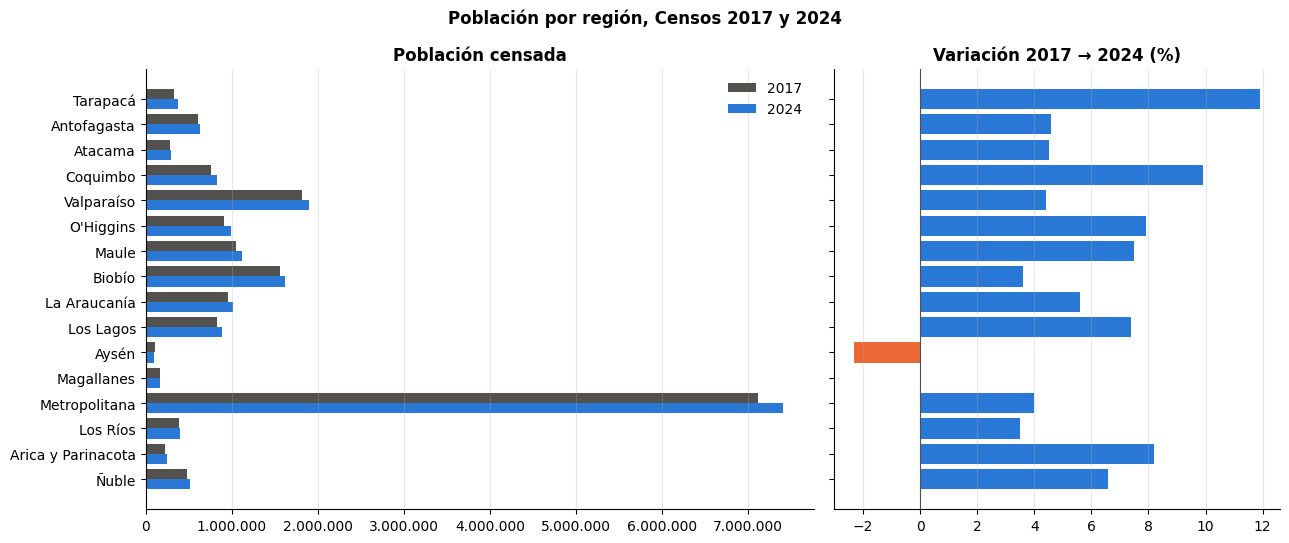

In [13]:
COLORES = {"2017": "#52514e", "2024": "#2a78d6"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [3, 2]}, sharey=True)
y = range(len(por_region))
alto = 0.4
ax1.barh([i - alto / 2 for i in y], por_region[2017], height=alto, label="2017", color=COLORES["2017"])
ax1.barh([i + alto / 2 for i in y], por_region[2024], height=alto, label="2024", color=COLORES["2024"])
ax1.set_yticks(list(y))
ax1.set_yticklabels(por_region.index)
ax1.invert_yaxis()
ax1.set_title("Población censada", fontweight="bold")
ax1.xaxis.set_major_formatter(miles)
ax1.legend(frameon=False)

colores_var = ["#eb6834" if v < 0 else "#2a78d6" for v in por_region["variación %"]]
ax2.barh(list(y), por_region["variación %"], color=colores_var)
ax2.axvline(0, color="#52514e", linewidth=0.8)
ax2.set_title("Variación 2017 → 2024 (%)", fontweight="bold")

for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Población por región, Censos 2017 y 2024", fontweight="bold")
plt.tight_layout()
plt.show()

---
## 5. Caso 2: pirámide de población

Pregunta: **¿cómo cambió la estructura por edad y sexo entre 2017 y 2024?**

No hace falta cruzar con nada: `grupo_etario` y `sexo` son columnas de `personas`.

> **Cuidado con el orden.** `grupo_etario` es texto (`'0-4'`, `'5-9'`, ..., `'85 o más'`). Ordenado
> alfabéticamente, `'5-9'` queda después de `'45-49'`. Hay que fijar el orden a mano.

In [14]:
ORDEN_EDAD = ["0-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34", "35-39", "40-44",
              "45-49", "50-54", "55-59", "60-64", "65-69", "70-74", "75-79", "80-84", "85 o más"]

edades = con.execute("""
    SELECT year, grupo_etario, sexo, COUNT(*) AS personas
    FROM personas
    GROUP BY ALL
""").df()

# Porcentaje sobre la población total de cada censo, para que 2017 y 2024 sean comparables
edades["porcentaje"] = edades["personas"] / edades.groupby("year")["personas"].transform("sum") * 100

piramide = edades.pivot_table(index="grupo_etario", columns=["year", "sexo"], values="porcentaje").reindex(ORDEN_EDAD)
piramide.round(2)

year           2017         2024      
sexo         hombre mujer hombre mujer
grupo_etario                          
0-4            3.38  3.26   2.40  2.31
5-9            3.52  3.37   3.16  3.05
10-14          3.33  3.20   3.47  3.33
15-19          3.62  3.46   3.39  3.21
20-24          4.00  3.90   3.50  3.39
25-29          4.22  4.16   3.75  3.73
30-34          3.67  3.69   4.11  4.16
35-39          3.39  3.48   3.75  3.87
40-44          3.34  3.48   3.33  3.54
45-49          3.20  3.40   2.97  3.26
50-54          3.24  3.50   3.01  3.34
55-59          2.84  3.12   2.87  3.26
60-64          2.27  2.55   2.71  3.12
65-69          1.73  1.99   2.18  2.53
70-74          1.33  1.61   1.58  1.91
75-79          0.88  1.18   1.13  1.45
80-84          0.54  0.82   0.70  1.02
85 o más       0.44  0.88   0.50  0.99

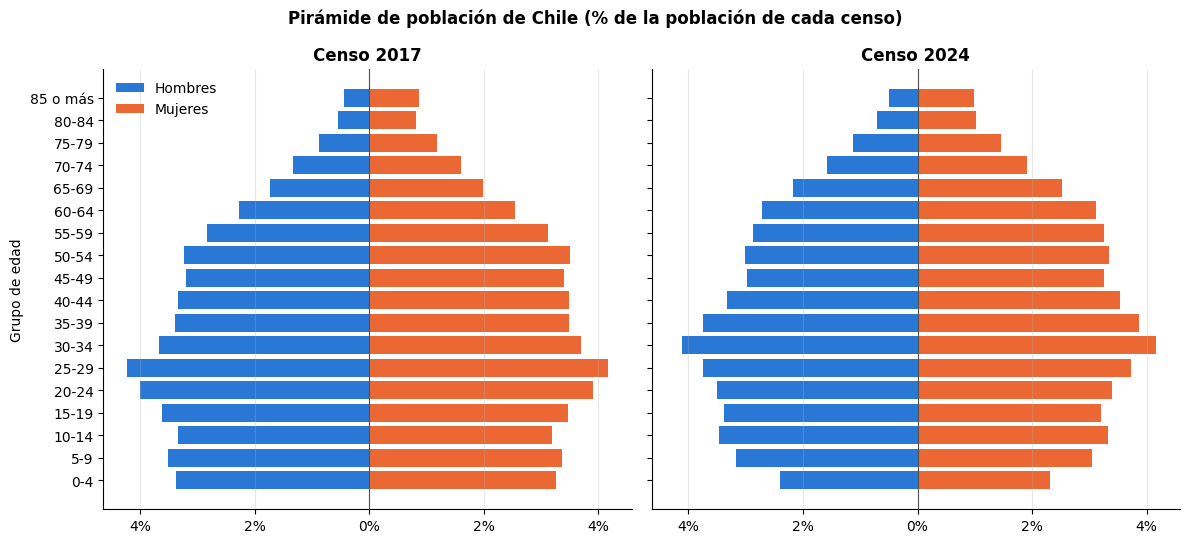

Personas de 65 años o más: 11.4 % (2017) → 14.0 % (2024)
Personas de 0 a 14 años  : 20.1 % (2017) → 17.7 % (2024)


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, sharex=True)
for ax, anio in zip(axes, [2017, 2024]):
    ax.barh(ORDEN_EDAD, -piramide[(anio, "hombre")], color="#2a78d6", label="Hombres")
    ax.barh(ORDEN_EDAD, piramide[(anio, "mujer")], color="#eb6834", label="Mujeres")
    ax.set_title(f"Censo {anio}", fontweight="bold")
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(v):.0f}%"))
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Grupo de edad")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Pirámide de población de Chile (% de la población de cada censo)", fontweight="bold")
plt.tight_layout()
plt.show()

mayores = edades[edades["grupo_etario"].isin(ORDEN_EDAD[13:])].groupby("year")["porcentaje"].sum().round(1)
menores = edades[edades["grupo_etario"].isin(ORDEN_EDAD[:3])].groupby("year")["porcentaje"].sum().round(1)
print(f"Personas de 65 años o más: {mayores[2017]} % (2017) → {mayores[2024]} % (2024)")
print(f"Personas de 0 a 14 años  : {menores[2017]} % (2017) → {menores[2024]} % (2024)")

---
## 6. Caso 3: tipo de vivienda (y qué hacer cuando las etiquetas cambian)

Pregunta: **¿qué tipo de vivienda predomina y cómo cambió?**

Esta variable existe en los dos censos, pero el INE **cambió algunas etiquetas** entre uno y otro
(por ejemplo `departamento en edificio` pasó a `departamento`). Si se agrupa directamente por
`tipo_vivienda`, la misma categoría aparece como dos filas distintas, una por año.

In [16]:
con.execute("""
    SELECT tipo_vivienda,
           COUNT(*) FILTER (WHERE year = 2017) AS viviendas_2017,
           COUNT(*) FILTER (WHERE year = 2024) AS viviendas_2024
    FROM viviendas
    GROUP BY ALL
    ORDER BY COALESCE(viviendas_2017, 0) + COALESCE(viviendas_2024, 0) DESC
""").df()

,tipo_vivienda,viviendas_2017,viviendas_2024
0,casa,5167728,5937284
1,departamento,0,1579970
2,departamento en edificio,1138062,0
3,pieza en casa antigua o en conventillo,53150,51305
4,"mediagua, mejora, rancho o choza",90714,0
5,otro tipo de vivienda particular,31422,38823
6,"mediagua, mejora, vivienda de emergencia, rancho o choza",0,27490
7,None,0,26070
8,vivienda colectiva,12822,0
9,"vivienda tradicional indígena (ruka, pae pae u otras)",3556,0


Se ve que `departamento en edificio` solo existe en 2017 y `departamento` solo en 2024, igual que
las variantes de *mediagua* y *vivienda tradicional indígena*. Se unifican con un diccionario
(2024 como referencia) y se dejan fuera las filas que no son viviendas particulares comparables:
las colectivas y los operativos calle y de personas en tránsito de 2017, y las filas sin tipo
informado.

In [17]:
UNIFICAR_TIPO = {
    "departamento en edificio": "departamento",
    "mediagua, mejora, rancho o choza": "mediagua, mejora, vivienda de emergencia, rancho o choza",
    "vivienda tradicional indígena (ruka, pae pae u otras)": "vivienda tradicional indígena (ruka u otras)",
}
EXCLUIR_TIPO = ["vivienda colectiva", "operativo calle (no es vivienda)",
                "operativo personas en tránsito (no es vivienda)"]

tipos = con.execute("""
    SELECT year, tipo_vivienda, COUNT(*) AS viviendas
    FROM viviendas
    WHERE tipo_vivienda IS NOT NULL
    GROUP BY ALL
""").df()
tipos = tipos[~tipos["tipo_vivienda"].isin(EXCLUIR_TIPO)].copy()
tipos["tipo_vivienda"] = tipos["tipo_vivienda"].replace(UNIFICAR_TIPO)
tipos = tipos.groupby(["year", "tipo_vivienda"], as_index=False)["viviendas"].sum()
tipos["porcentaje"] = tipos["viviendas"] / tipos.groupby("year")["viviendas"].transform("sum") * 100

comparacion = tipos.pivot(index="tipo_vivienda", columns="year", values=["viviendas", "porcentaje"])
comparacion = comparacion.sort_values(("viviendas", 2024), ascending=False)
comparacion["porcentaje"] = comparacion["porcentaje"].round(2)
comparacion["viviendas"] = comparacion["viviendas"].astype("Int64")
comparacion

viviendas          porcentaje       
year                                                          2017     2024       2017   2024
tipo_vivienda                                                                                
casa                                                       5167728  5937284      79.67  77.73
departamento                                               1138062  1579970      17.54  20.68
pieza en casa antigua o en conventillo                       53150    51305       0.82   0.67
otro tipo de vivienda particular                             31422    38823       0.48   0.51
mediagua, mejora, vivienda de emergencia, rancho o choza     90714    27490       1.40   0.36
vivienda tradicional indígena (ruka u otras)                  3556     1967       0.05   0.03
móvil (carpa, casa rodante o similar)                         1901     1557       0.03   0.02

La casa concentra casi el 80 % de las viviendas, así que un gráfico de porcentajes apenas deja ver
el resto. Es más informativo mirar **cuánto cambió la participación de cada tipo** (en puntos
porcentuales):

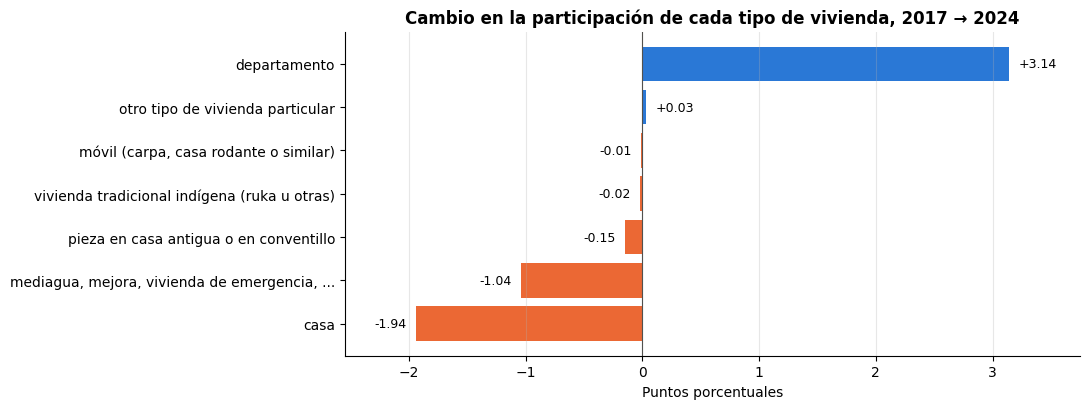

In [18]:
cambio = (comparacion[("porcentaje", 2024)] - comparacion[("porcentaje", 2017)]).sort_values()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.barh([t if len(t) < 45 else t[:42] + "..." for t in cambio.index], cambio.values,
        color=["#eb6834" if v < 0 else "#2a78d6" for v in cambio.values])
ax.axvline(0, color="#52514e", linewidth=0.8)
for i, v in enumerate(cambio.values):
    ax.text(v + (0.08 if v >= 0 else -0.08), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.margins(x=0.12)
ax.set_xlabel("Puntos porcentuales")
ax.set_title("Cambio en la participación de cada tipo de vivienda, 2017 → 2024", fontweight="bold")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

---
## 7. Caso 4: hogares con internet fijo por región (2024)

Pregunta: **¿qué porcentaje de los hogares tiene internet fijo en cada región?**

`tiene_internet_fijo` es una variable de `hogares` que **solo existe en 2024** (se puede comprobar
con `variables("hogares", "internet")`). La región se obtiene por la vivienda, con la vista
`hogares_comuna`.

In [19]:
variables("hogares", "internet")

,variable,2017,2024,descripcion
0,tiene_internet_fijo,–,✓,Si el hogar dispone de internet fijo. Etiqueta de la categoría según el diccionario del INE. Sol...
1,tiene_internet_movil,–,✓,Si el hogar dispone de internet móvil. Etiqueta de la categoría según el diccionario del INE. So...
2,tiene_internet_satelital,–,✓,Si el hogar dispone de internet satelital. Etiqueta de la categoría según el diccionario del INE...


In [20]:
internet = con.execute("""
    SELECT c.cod_region, COUNT(*) AS hogares,
           COUNT(*) FILTER (WHERE h.tiene_internet_fijo = 'sí') AS con_internet_fijo
    FROM hogares_comuna h
    JOIN comunas c USING (cod_comuna)
    WHERE h.year = 2024
      AND h.tiene_internet_fijo IN ('sí', 'no')     -- se excluyen 'no responde' y filas sin dato
    GROUP BY ALL
""").df()
internet["region"] = internet["cod_region"].map(REGIONES)
internet["porcentaje"] = (internet["con_internet_fijo"] / internet["hogares"] * 100).round(1)
internet = internet.sort_values("porcentaje", ascending=False).reset_index(drop=True)
internet[["region", "hogares", "con_internet_fijo", "porcentaje"]]

,region,hogares,con_internet_fijo,porcentaje
0,Metropolitana,2596881,1951589,75.2
1,Magallanes,62969,46902,74.5
2,Antofagasta,213363,157716,73.9
3,Arica y Parinacota,80553,55391,68.8
4,Tarapacá,121371,82000,67.6
5,Valparaíso,700086,452058,64.6
6,Biobío,578856,373242,64.5
7,Coquimbo,292250,166999,57.1
8,O'Higgins,350081,192141,54.9
9,Atacama,102851,55765,54.2


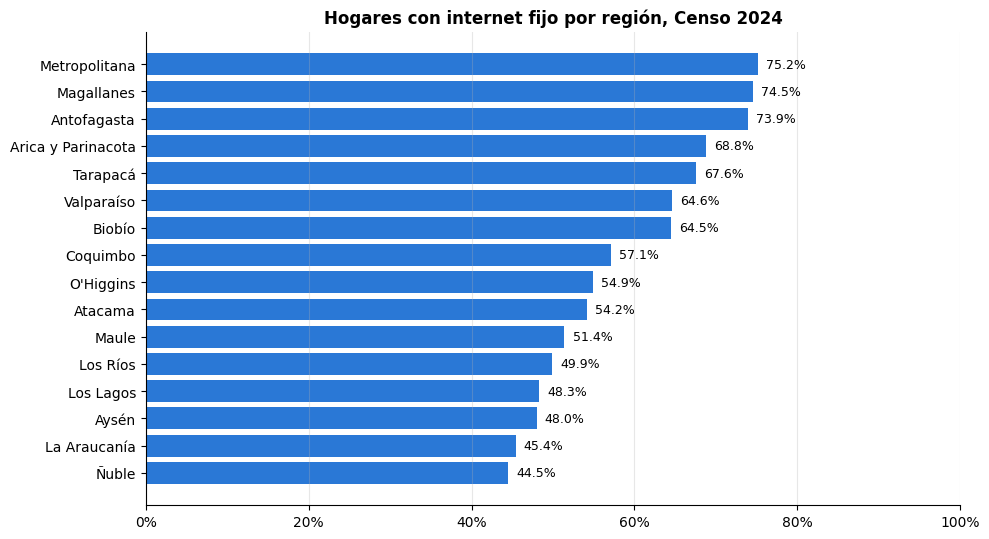

In [21]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(internet["region"], internet["porcentaje"], color="#2a78d6")
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
for i, v in enumerate(internet["porcentaje"]):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("Hogares con internet fijo por región, Censo 2024", fontweight="bold")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

---
## 8. Formato largo: una consulta para cualquier pregunta

En el **formato largo** cada fila es una respuesta: (`id_vivienda`, ..., `pregunta`, `respuesta`).
El texto de `pregunta` es la `descripcion_pregunta` del diccionario `preguntas-respuestas-censo`
(todas las preguntas del largo de viviendas y hogares figuran en él). Eso permite **buscar una
pregunta por texto** y consultarla sin saber cómo se llama su columna en el formato ancho.

### Buscar una pregunta por texto

In [22]:
def buscar_pregunta(texto):
    """Preguntas del diccionario cuyo nombre o enunciado contiene `texto`, por año y tipo de registro."""
    return con.execute(
        """
        SELECT year, tipo_registro, descripcion_pregunta,
               MIN(nombre_pregunta) AS nombre_en_la_fuente,
               COUNT(num_respuesta) AS respuestas_codificadas
        FROM preguntas
        WHERE descripcion_pregunta ILIKE ? OR enunciado_pregunta ILIKE ?
        GROUP BY year, tipo_registro, descripcion_pregunta
        ORDER BY tipo_registro, descripcion_pregunta, year
        """,
        [f"%{texto}%"] * 2,
    ).df()


def respuestas_de(descripcion_pregunta, anio=2024, tipo_registro="vivienda"):
    """Códigos y etiquetas de respuesta de una pregunta (tipo_registro en singular: vivienda, hogar, persona)."""
    return con.execute(
        """
        SELECT year, nombre_pregunta, num_respuesta, valor_respuesta
        FROM preguntas
        WHERE descripcion_pregunta = ? AND year = ? AND tipo_registro = ?
        ORDER BY TRY_CAST(num_respuesta AS INTEGER), num_respuesta
        """,
        [descripcion_pregunta, anio, tipo_registro],
    ).df()


buscar_pregunta("agua")

,year,tipo_registro,descripcion_pregunta,nombre_en_la_fuente,respuestas_codificadas
0,2024,vivienda,distribución del agua,p7_distrib_agua,5
1,2017,vivienda,procedencia de agua,p05,6
2,2024,vivienda,procedencia de agua,p6_fuente_agua,6


In [23]:
respuestas_de("procedencia de agua", anio=2024, tipo_registro="vivienda")

,year,nombre_pregunta,num_respuesta,valor_respuesta
0,2024,p6_fuente_agua,-99,no responde
1,2024,p6_fuente_agua,1,red pública
2,2024,p6_fuente_agua,2,pozo o noria
3,2024,p6_fuente_agua,3,camión aljibe
4,2024,p6_fuente_agua,4,"río, vertiente, estero, canal, lago, agua lluvia, etc."
5,2024,p6_fuente_agua,na,no aplica


### Una función para cualquier pregunta, en los dos censos

Con el formato largo la consulta es siempre la misma: filtrar `pregunta` y contar `respuesta`. Una
sola función sirve para cualquier pregunta y lee **los dos censos en una pasada**, sin elegir
columnas ni unir esquemas distintos.

Hay un límite: solo funciona con preguntas que **se llaman igual en 2017 y 2024**. El diccionario
dice cuáles son:

In [24]:
preguntas_comunes = con.execute("""
    SELECT tipo_registro, descripcion_pregunta AS pregunta
    FROM preguntas
    GROUP BY ALL
    HAVING COUNT(DISTINCT year) = 2
    ORDER BY ALL
""").df()
print(preguntas_comunes.groupby("tipo_registro").size().rename("preguntas con el mismo texto en ambos censos").to_string())
preguntas_comunes[preguntas_comunes["tipo_registro"] == "vivienda"]

tipo_registro
hogar        2
persona     15
vivienda    10


,tipo_registro,pregunta
17,vivienda,comparten gastos de alimentación
18,vivienda,dormitorios
19,vivienda,grupos separados por gastos en alimentación
20,vivienda,material de construcción de cubierta del techo
21,vivienda,material de construcción de paredes
22,vivienda,material de construcción del piso
23,vivienda,procedencia de agua
24,vivienda,tipo de vivienda
25,vivienda,total de hogares
26,vivienda,total de personas


El resto cambió de redacción (`estado de ocupación` en 2017 es `estado de ocupación de la vivienda`
en 2024) o existe en un solo censo. El diccionario es algo más amplio que lo publicado en el largo:
en viviendas lista 10 preguntas comunes, pero el largo de 2017 solo trae datos de 8 (faltan las dos
de gastos de alimentación). Con las que sí coinciden, la función es:

In [25]:
def distribucion_pregunta(preguntas, tipo_registro="viviendas"):
    """Reparto de respuestas de una o varias preguntas del formato largo, 2017 y 2024 lado a lado.

    Filtra `respuesta IS NOT NULL`: el largo de 2017 trae filas con respuesta nula que el de 2024 no
    publica; sin el filtro, los porcentajes de ambos años no serían comparables.
    """
    if isinstance(preguntas, str):
        preguntas = [preguntas]
    df = con.execute(
        f"""
        SELECT year, pregunta, respuesta, COUNT(*) AS registros
        FROM {leer_censo(BASE_LARGO, tipo_registro)}
        WHERE list_contains(?, pregunta) AND respuesta IS NOT NULL
        GROUP BY ALL
        """,
        [preguntas],
    ).df()
    df["porcentaje"] = (
        df["registros"] / df.groupby(["year", "pregunta"])["registros"].transform("sum") * 100
    ).round(2)
    tabla = df.pivot(index=["pregunta", "respuesta"], columns="year", values=["registros", "porcentaje"])
    orden = (df.groupby(["pregunta", "respuesta"], as_index=False)["registros"].sum()
               .sort_values(["pregunta", "registros"], ascending=[True, False])
               .set_index(["pregunta", "respuesta"]).index)
    tabla = tabla.reindex(orden)
    tabla["registros"] = tabla["registros"].astype("Int64")
    return tabla


# Dos preguntas distintas con la misma función. Lee viviendas en formato largo (~180 millones de
# filas entre los dos censos): toma alrededor de un minuto.
agua_y_paredes = distribucion_pregunta(["procedencia de agua", "material de construcción de paredes"])
agua_y_paredes

registros          porcentaje       
year                                                                                                                         2017     2024       2017   2024
pregunta                            respuesta                                                                                                               
material de construcción de paredes tabique forrado por ambas caras (madera o acero)                                      1307189  1854738      23.73  28.94
                                    albañilería: bloque de cemento, ladrillo o piedra                                        <NA>  2754185        NaN  42.98
                                    hormigón armado                                                                       1234116  1499949      22.40  23.41
                                    albañilería: bloque de cemento, piedra o ladrillo                                     2445790     <NA>      44.40    NaN
                                    tabique sin forro interior (madera u otro)                                             335072   176313       6.08   2.75
                                    adobe, barro, quincha, pirca u otro artesanal tradicional                              121756     <NA>       2.21    NaN
                                    adobe, barro, pirca, quincha u otro material artesanal                                   <NA>   106790        NaN   1.67
                                    materiales precarios (lata, cartón, plástico, etc.)                                     40682     <NA>       0.74    NaN
                                    missing                                                                                 23836     <NA>       0.43    NaN
                                    materiales precarios o de desecho: cartón, sacos, trozos de latas o plásticos, etc.      <NA>    14752        NaN   0.23
                                    no responde                                                                              <NA>     1445        NaN   0.02
procedencia de agua                 red pública                                                                           5086491  5914136      92.34  92.29
                                    pozo o noria                                                                           219003   263309       3.98   4.11
                                    camión aljibe                                                                           71279   131141       1.29   2.05
                                    río, vertiente, estero, canal, lago, agua lluvia, etc.                                   <NA>    98243        NaN   1.53
                                    río, vertiente, estero, canal, lago, etc.                                               92922     <NA>       1.69    NaN
                                    missing                                                                                 38746     <NA>       0.70    NaN
                                    no responde                                                                              <NA>     1343        NaN   0.02

**Mismo texto de pregunta no garantiza las mismas etiquetas de respuesta.** El INE reescribió
algunas categorías entre censos (`albañilería: bloque de cemento, ladrillo o piedra` en 2024 es
`...piedra o ladrillo` en 2017) y la no respuesta se llama `missing` en 2017 y `no responde` en
2024. Esas categorías quedan en filas separadas, con `<NA>` en el año donde no existen, igual que en
el caso 3: para compararlas hay que unificar las etiquetas a mano.

Se puede comprobar contra el formato ancho: `procedencia de agua` es la columna `fuente_agua`.
Debe dar exactamente la misma cuenta, en los dos censos:

In [26]:
largo_agua = agua_y_paredes["registros"].loc["procedencia de agua"].fillna(0).astype(int)

ancho_agua = (
    con.execute("""
        SELECT year, fuente_agua AS respuesta, COUNT(*) AS registros
        FROM viviendas
        WHERE fuente_agua IS NOT NULL
        GROUP BY ALL
    """).df()
    .pivot(index="respuesta", columns="year", values="registros")
    .reindex(largo_agua.index).fillna(0).astype(int)
)
print("¿Largo y ancho dan la misma cuenta en las dos fechas?", bool((largo_agua == ancho_agua).all().all()))
ancho_agua

¿Largo y ancho dan la misma cuenta en las dos fechas? True


year,2017,2024
respuesta,,
red pública,5086491,5914136
pozo o noria,219003,263309
camión aljibe,71279,131141
"río, vertiente, estero, canal, lago, agua lluvia, etc.",0,98243
"río, vertiente, estero, canal, lago, etc.",92922,0
missing,38746,0
no responde,0,1343


> **Respuestas nulas en el largo de 2017.** El largo de 2024 no publica respuestas vacías, pero el
> de 2017 sí trae filas con `respuesta` nula (cerca de 5 millones en viviendas, y 13 mil en
> hogares): por ejemplo, 991.133 viviendas sin dato en `procedencia de agua`, que en el ancho son
> `fuente_agua` nulo. Por eso la función filtra `respuesta IS NOT NULL`. Con ese filtro, ambos
> censos se cuentan igual.

### ¿Cuándo conviene cada formato?

| | Ancho (`v1w`) | Largo (`v1l`) |
|---|---|---|
| **Tamaño** | ~62 millones de filas | más de 25 veces más filas (una por pregunta respondida) |
| **Una variable** | `GROUP BY` sobre la columna | `WHERE pregunta = '...'` y contar `respuesta` |
| **Cruzar variables** (p. ej. material de paredes × tipo de vivienda) | Un `GROUP BY` con dos columnas | Hay que unir la tabla consigo misma por vivienda, hogar o persona |
| **Números** (edad, escolaridad) | Columnas numéricas | `respuesta` es siempre texto |
| **Saber qué columna es** | `variables()` o el `dataset.json` | Se busca por el texto de la pregunta |
| **Misma consulta para muchas preguntas** | Hay que nombrar cada columna | Se cambia solo el texto de la pregunta |
| **Preguntas de un solo censo** | Columna nula en el otro año | La pregunta simplemente no aparece |

**Regla práctica:** el **ancho** para analizar (cruces, números, volumen: es lo que usan los casos 1
a 4). El **largo** para explorar o para repetir una misma consulta sobre varias preguntas que se
llaman igual en ambos censos, como en la función de arriba.

> **No recorras `personas` completo en formato largo.** Son más de 1.300 millones de filas entre
> 2017 y 2024: leerlas enteras toma varios minutos y no hace falta, porque todo lo de personas está
> también en el formato ancho. Si necesitas el largo de personas, filtra siempre por `year` y
> `tipo_registro` (carpetas del path) y trabaja de a un año.

---
## 9. Tu propia consulta

Cambia `TABLA` y `COLUMNA` y ejecuta. Si no sabes qué columna usar, parte de `variables(TABLA, "texto")`.
La celda muestra cómo se reparten las respuestas en cada censo (porcentaje sobre los registros con
valor, incluidas categorías como `no responde`). Con el ejemplo se ve además que **la categoría de
no respuesta se llama distinto en cada censo**: `missing` en 2017 y `no responde` en 2024.

In [27]:
variables("personas", "pueblo")

,variable,2017,2024,descripcion
0,es_de_pueblo_originario,✓,✓,Si la persona se considera perteneciente a un pueblo indígena u originario. Etiqueta de la categ...
1,pueblo_originario,✓,✓,Pueblo indígena u originario al que pertenece. Etiqueta de la categoría según el diccionario del...
2,grupo_pueblo_originario,✓,–,Agrupación del pueblo originario. Etiqueta de la categoría según el diccionario del INE. Solo en...
3,afrodescendencia,–,✓,Pueblo o grupo afrodescendiente con que se identifica. Etiqueta de la categoría según el diccion...


In [28]:
TABLA = "personas"                      # viviendas, hogares o personas
COLUMNA = "es_de_pueblo_originario"     # cualquier variable categórica de esa tabla

validas = con.execute(f"DESCRIBE {TABLA}").df()["column_name"].tolist()
if COLUMNA not in validas:
    raise ValueError(f"'{COLUMNA}' no es una columna de {TABLA}. Prueba con variables('{TABLA}', 'texto').")

mi_distribucion = con.execute(f"""
    SELECT year, {COLUMNA} AS respuesta, COUNT(*) AS registros
    FROM {TABLA}
    WHERE {COLUMNA} IS NOT NULL
    GROUP BY ALL
""").df()
mi_distribucion["porcentaje"] = (
    mi_distribucion["registros"] / mi_distribucion.groupby("year")["registros"].transform("sum") * 100
).round(2)
mi_tabla = mi_distribucion.pivot(index="respuesta", columns="year", values=["registros", "porcentaje"])
mi_tabla["registros"] = mi_tabla["registros"].astype("Int64")
mi_tabla

registros           porcentaje       
year             2017      2024       2017   2024
respuesta                                        
missing        497927      <NA>       2.83    NaN
no           14890284  16267072      84.73  88.02
no responde      <NA>    107497        NaN   0.58
sí            2185792   2105863      12.44  11.40

### Notas

- **Dos censos, dos cuestionarios.** Muchas variables existen en uno solo (por ejemplo, internet en
  el hogar solo en 2024) y algunas cambian de etiqueta. Antes de comparar años, revisar
  `variables()` y las categorías de cada año.
- **Largo de 2017: respuestas nulas.** Trae filas con `respuesta` nula que el de 2024 no publica;
  filtrar `respuesta IS NOT NULL` antes de comparar años (ver sección 8).
- **Nulo no significa "no".** En el formato ancho cada partición guarda solo sus columnas: una
  variable que no existe en un año o tipo de registro se lee como nulo. Además hay categorías
  explícitas como `no responde`, `no aplica` o `missing` (2017) que conviene excluir (o analizar) a propósito.
- **Los ids de 2017 son relativos a la zona censal.** Para unir viviendas, hogares y personas en
  2017 hay que usar `id_zona_censal_local` junto con `id_vivienda` (ver sección 3).
- **Solo `viviendas` trae `cod_comuna`.** Hogares y personas llegan a la comuna por su vivienda.
- **Nombres normalizados.** Las regiones y comunas vienen en minúsculas y sin tildes
  (`valparaiso`). Para mostrarlas, usar un diccionario de nombres cortos como `REGIONES`.
- **Comunas con pocos habitantes (2024).** `division-territorial-censal` marca con
  `comuna_bajo_umbral_habitantes` las comunas con menos de 6.000 personas censadas.
- **Rendimiento.** Contar o agrupar sobre una tabla ancha de un año toma segundos; cruzar personas
  con viviendas en los dos censos, alrededor de un minuto. El formato largo es mucho más pesado:
  filtrar siempre por `year` y `tipo_registro`.
- `flags_procesamiento` es una columna técnica (transformaciones del ETL) y no suele hacer falta.

---

*Datos provistos por [Data Observatory](https://dataobservatory.net) · Fuente: INE, Censos de Población y Vivienda 2017 y 2024*